# Detecting Outliers with Z-scores

**Learning goals**
- Interpret a Z-score as a distance from the mean in standard-deviation units.
- Compute Z-scores and flag observations using an explicit threshold.
- Visualize the result and explain why the method can miss unusual observations.


## 1. Import the libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, RED = '#2463a6', '#d44335'


## 2. Generate reproducible data
We generate 200 synthetic measurements from a normal distribution with population mean 100 and population standard deviation 5. The **sample** mean and standard deviation will usually differ from these values. A fixed random seed makes the lesson reproducible within the same software environment.

,Data
0,101.523585
1,94.800079
2,103.752256
3,104.702824
4,90.244824


,Data
count,200.000
mean,99.848
std,4.410
min,89.340
25%,96.717
50%,99.741
75%,102.675
max,114.569


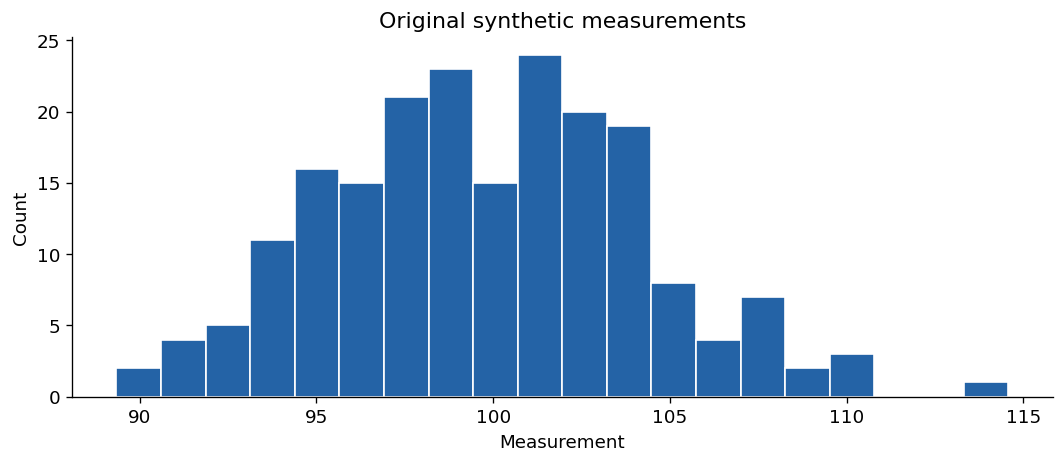

In [ ]:
rng = np.random.default_rng(42)
original = pd.DataFrame({'Data': rng.normal(loc=100, scale=5, size=200)})
display(original.head())
display(original.describe().round(3))
fig, ax = plt.subplots()
ax.hist(original['Data'], bins=20, color=BLUE, edgecolor='white')
ax.set(title='Original synthetic measurements', xlabel='Measurement', ylabel='Count')
plt.tight_layout()
plt.show()

## 3. Insert two known extreme observations
Create an independent copy to preserve the original data. Replace the observations at index 50 and 90 with −40 and 180. These are deliberately injected values, not automatically detected outliers yet.

In [ ]:
df = original.copy()
df.loc[50, 'Data'] = -40
df.loc[90, 'Data'] = 180
summary = pd.DataFrame({
    'Original': original['Data'].agg(['mean', 'std', 'min', 'max']),
    'With injected values': df['Data'].agg(['mean', 'std', 'min', 'max'])
})
display(summary.round(3))

,Original,With injected values
mean,99.848,99.524
std,4.410,12.240
min,89.340,-40.000
max,114.569,180.000


## 4. Compute Z-scores
For a sample, we use

$$z_i=\frac{x_i-\bar{x}}{s},\qquad s=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}.$$

- $z=0$: at the sample mean.
- $z=2$: two sample standard deviations above the mean.
- $z=-2$: two sample standard deviations below the mean.

We flag an observation when **$|z|>3$**. Equality to 3 is not flagged in this lesson. For a normal population with known parameters, about 99.73% of observations fall within three standard deviations of the mean. This motivates the rule; it is not a universal guarantee for real data or sample-estimated Z-scores.

Here we estimate both parameters from the dataset **including the injected observations**. pandas uses the sample standard deviation (`ddof=1`), which we specify explicitly.

In [ ]:
threshold = 3.0
mean = df['Data'].mean()
std = df['Data'].std(ddof=1)
if not np.isfinite(std) or std == 0:
    raise ValueError('Z-scores require a finite, nonzero standard deviation.')
df['Z_score'] = (df['Data'] - mean) / std
df['outlier'] = df['Z_score'].abs() > threshold
lower, upper = mean - threshold * std, mean + threshold * std
print(f'Mean = {mean:.3f}; sample standard deviation = {std:.3f}')
print(f'Unflagged interval: [{lower:.3f}, {upper:.3f}]')
display(df.loc[df['outlier']].round(3))
print(f"Flagged: {df['outlier'].sum()} / {len(df)}")

Mean = 99.524; sample standard deviation = 12.240
Unflagged interval: [62.803, 136.245]


,Data,Z_score,outlier
50,-40.0,-11.399,True
90,180.0,6.575,True


Flagged: 2 / 200


## 5. Visualize the decision
The horizontal axis is the observation index, not time. Dashed lines show the detection thresholds.

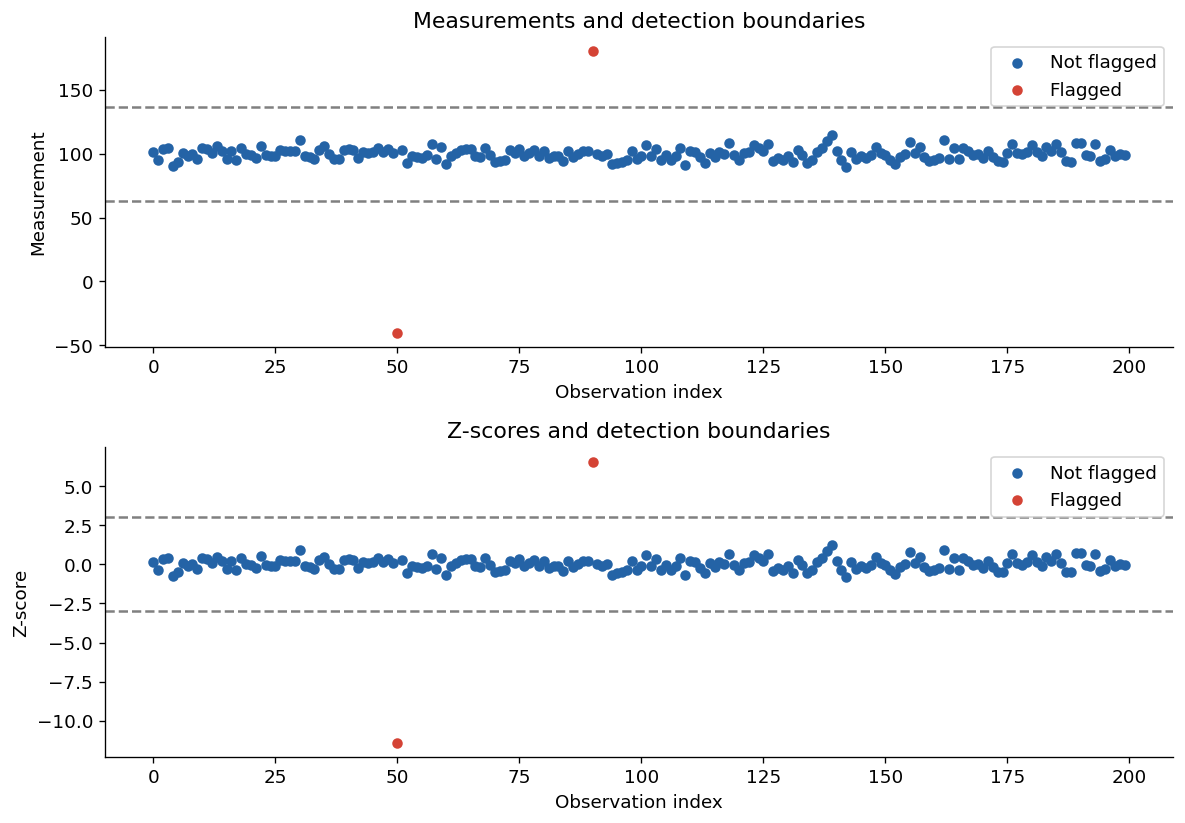

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
for ax, column, limits, title, ylabel in [
    (axes[0], 'Data', (lower, upper), 'Measurements and detection boundaries', 'Measurement'),
    (axes[1], 'Z_score', (-threshold, threshold), 'Z-scores and detection boundaries', 'Z-score')
]:
    for flag, color, label in [(False, BLUE, 'Not flagged'), (True, RED, 'Flagged')]:
        subset = df.loc[df['outlier'] == flag]
        ax.scatter(subset.index, subset[column], color=color, label=label, s=28)
    for boundary in limits:
        ax.axhline(boundary, color='gray', linestyle='--')
    ax.set(title=title, xlabel='Observation index', ylabel=ylabel)
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 6. Explore the threshold
Predict the result before running: can increasing the threshold increase the number flagged if the data and Z-scores stay fixed?

In [ ]:
display(pd.DataFrame({
    'Threshold': [2.0, 2.5, 3.0, 3.5],
    'Number flagged': [int((df['Z_score'].abs() > t).sum()) for t in [2.0, 2.5, 3.0, 3.5]]
}))

,Threshold,Number flagged
0,2.0,2
1,2.5,2
2,3.0,2
3,3.5,2


## 7. A limitation: extreme values can hide one another
Outliers can inflate the mean and standard deviation. This can make a moderately unusual observation look less extreme, a phenomenon called **masking**. Compare the Z-score of 130 when the same dataset also contains a much larger value.

In [ ]:
moderate = np.append(original['Data'].to_numpy(), 130.0)
with_extreme = np.append(moderate, 1000.0)
rows = []
for label, values in [('Add 130 only', moderate), ('Add 130 and 1000', with_extreme)]:
    m, s = values.mean(), values.std(ddof=1)
    score = (130 - m) / s
    rows.append({'Scenario': label, 'Mean': m, 'Std': s,
                 'Z-score of 130': score, '130 flagged': abs(score) > 3})
display(pd.DataFrame(rows).round(3))

,Scenario,Mean,Std,Z-score of 130,130 flagged
0,Add 130 only,99.998,4.886,6.141,True
1,Add 130 and 1000,104.453,63.511,0.402,False


## 8. What should happen after detection?
Investigate data-entry errors, measurement problems and domain context. A rare but valid observation may be important. Possible actions include correcting verified errors, retaining valid observations, or using an appropriate robust method.

The next cell demonstrates filtering **only because the injected values in this synthetic lesson are known**. It preserves `df`. It does not restore the original values at those indices.

In [ ]:
filtered = df.loc[~df['outlier'], ['Data']].copy()
print(f'Before: {len(df)} rows; after illustrative filtering: {len(filtered)} rows')

Before: 200 rows; after illustrative filtering: 198 rows





**Takeaway:** Z-scores measure distance relative to the mean and standard deviation. Their interpretation depends on the distribution and the quality of those estimates.
